<a href="https://colab.research.google.com/github/soundoussouna/cytokine-analysis/blob/main/Tp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [ ]:
conc = np.array([0, 2, 4, 6, 8, 10])                                        # µg/mL
absorbance = 0.0512 * conc + 0.004 + np.random.normal(0, 0.008, conc.size)
absorbance = absorbance.round(3)
pd.DataFrame({"concentration (µg/mL)": conc, "absorbance": absorbance})

,concentration (µg/mL),absorbance
0,0,0.000
1,2,0.099
2,4,0.208
3,6,0.303
4,8,0.425
5,10,0.522


In [ ]:
# 1) Droite de régression
pente, ordonnee = np.polyfit(conc, absorbance, 1)
# 2) Coefficient de détermination R²
A_calc = pente * conc + ordonnee                      # absorbance calculée par la droite
ss_res = np.sum((absorbance - A_calc) ** 2)                  # écarts entre mesure et droite
ss_tot = np.sum((absorbance - np.mean(absorbance)) ** 2)            # écarts entre mesure et moyenne
R2 = 1 - ss_res / ss_tot
# 3) Affichage
print(f"pente = {pente:.4f} | ordonnée = {ordonnee:.4f} | R² = {R2:.4f}")

pente = 0.0526 | ordonnée = -0.0036 | R² = 0.9992


Dans la cuvette : 5.96 µg/mL | Solution mère : 29.8 µg/mL


ValueError: Unrecognized marker style '...'

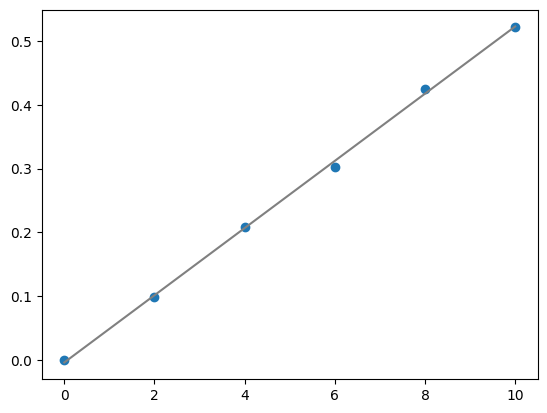

In [ ]:
A_inconnu = 0.310
dilution = 5
C_cuvette = (A_inconnu - ordonnee) / pente          # concentration dans la cuvette (µg/mL)
C_mere = C_cuvette * dilution                  # concentration de la solution mère (µg/mL)
print(f"Dans la cuvette : {C_cuvette:.2f} µg/mL | Solution mère : {C_mere:.1f} µg/mL")
# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")
# marker: l'étoile s'écrit "*"
plt.scatter(C_cuvette, A_inconnu, marker="", s=200, color="red", label="échantillon")
plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (µg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

Dans la cuvette : 5.96 µg/mL | Solution mère : 29.8 µg/mL


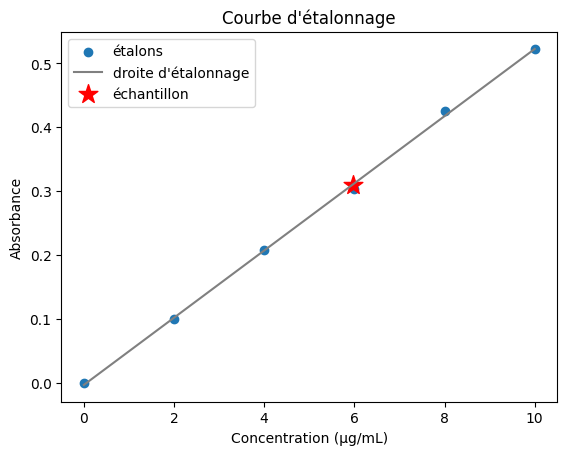

In [ ]:
A_inconnu = 0.310
dilution = 5
C_cuvette = (A_inconnu - ordonnee) / pente          # concentration dans la cuvette (µg/mL)
C_mere = C_cuvette * dilution                  # concentration de la solution mère (µg/mL)
print(f"Dans la cuvette : {C_cuvette:.2f} µg/mL | Solution mère : {C_mere:.1f} µg/mL")
# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")
# marker: l'étoile s'écrit "*"
plt.scatter(C_cuvette, A_inconnu, marker="*", s=200, color="red", label="échantillon")
plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (µg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

Votre reponse : Q1 = a , Q2 = b , Q3 = a

In [ ]:
def michaelis(S, Vmax, Km):
    return Vmax * S / (Km + S)
S = np.array([0.5, 1, 2, 5, 10, 20, 50, 100])                    # mM
# mM, concentration de l'inhibiteur
I = 10
v_sans = (michaelis(S, 120, 8) * np.random.normal(1, 0.04, S.size)).round(1)
v_avec = (michaelis(S, 120, 8 * (1 + I / 5)) * np.random.normal(1, 0.04, S.size)).round(1)
pd.DataFrame({"S (mM)": S, "v sans inhibiteur": v_sans, "v avec inhibiteur": v_avec})

,S (mM),v sans inhibiteur,v avec inhibiteur
0,0.5,7.3,2.3
1,1.0,12.7,4.8
2,2.0,24.0,9.0
3,5.0,45.5,21.0
4,10.0,69.0,34.2
5,20.0,82.0,55.5
6,50.0,109.5,78.2
7,100.0,115.2,97.3


In [ ]:
# Sans inhibiteur
param_sans, _ = curve_fit(michaelis, S, v_sans, p0=[100, 5])
Vmax_sans, Km_sans = param_sans
# Avec inhibiteur : même chose avec la deuxième série de vitesses
param_avec, _ = curve_fit(michaelis, S, v_avec, p0=[100, 5])
Vmax_avec, Km_avec = param_avec
pd.DataFrame({"Vmax": [Vmax_sans, Vmax_avec], "Km (mM)": [Km_sans, Km_avec]},
             index=["sans inhibiteur", "avec inhibiteur"]).round(1)

,Vmax,Km (mM)
sans inhibiteur,125.7,8.8
avec inhibiteur,119.5,24.3


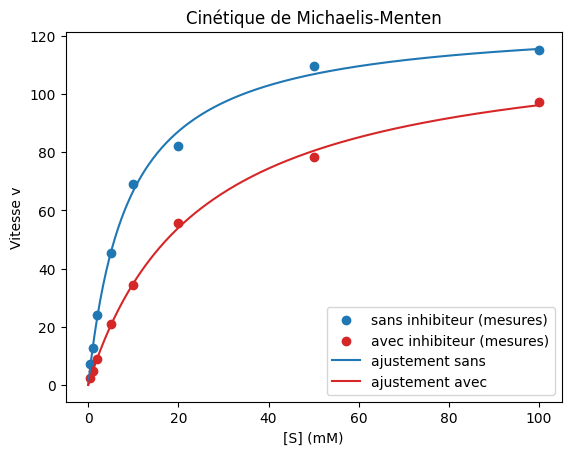

In [ ]:
S_fin = np.linspace(0, 100, 300)
plt.scatter(S, v_sans, color="tab:blue", label="sans inhibiteur (mesures)")
plt.scatter(S, v_avec, color="tab:red", label="avec inhibiteur (mesures)")
plt.plot(S_fin, michaelis(S_fin, Vmax_sans, Km_sans), color="tab:blue",
    label="ajustement sans")
plt.plot(S_fin, michaelis(S_fin, Vmax_avec, Km_avec), color="tab:red",
    label="ajustement avec")
plt.title("Cinétique de Michaelis-Menten")
plt.xlabel("[S] (mM)")
plt.ylabel("Vitesse v")
plt.legend()
plt.show()

In [ ]:
Ki = I / (Km_avec / Km_sans - 1)
print(f"Ki = {Ki:.1f} mM")

Ki = 5.7 mM


Votre reponse : Q1 = b , Q2 = a , Q3 = a

In [ ]:
def hill(logC, Emin, Emax, logEC50, n):
    return Emin + (Emax - Emin) / (1 + 10 ** ((logEC50 - logC) * n))
logC = np.arange(-9, -3.5, 0.5)                              # log10 de la concentration (M)
effet_A = (hill(logC, 2, 98, -7.0, 1.0) + rng.normal(0, 3, logC.size)).round(1)
effet_B = (hill(logC, 2, 98, -6.3, 1.0) + rng.normal(0, 3, logC.size)).round(1)
pd.DataFrame({"logC": logC, "effet A (%)": effet_A, "effet B (%)": effet_B})
